# Snowshoe hares at Bonanza Creek Experimental Forest
### Week 4 Tuesday

## Data Import

In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
import os

obs = pd.read_csv(os.path.join('data','55_Hare_Data_2012.txt'))

In [5]:
obs.head()

,date,time,grid,trap,l_ear,r_ear,sex,age,weight,hindft,notes,b_key,session_id,study
0,11/26/1998,NaN,bonrip,1A,414D096A08,NaN,NaN,NaN,1370.0,160.0,NaN,917.0,51,Population
1,11/26/1998,NaN,bonrip,2C,414D320671,NaN,M,NaN,1430.0,NaN,NaN,936.0,51,Population
2,11/26/1998,NaN,bonrip,2D,414D103E3A,NaN,M,NaN,1430.0,NaN,NaN,921.0,51,Population
3,11/26/1998,NaN,bonrip,2E,414D262D43,NaN,NaN,NaN,1490.0,135.0,NaN,931.0,51,Population
4,11/26/1998,NaN,bonrip,3B,414D2B4B58,NaN,NaN,NaN,1710.0,150.0,NaN,933.0,51,Population


In [6]:
obs.info()

<class 'pandas.DataFrame'>
RangeIndex: 3380 entries, 0 to 3379
Data columns (total 14 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   date        3380 non-null   str    
 1   time        264 non-null    str    
 2   grid        3380 non-null   str    
 3   trap        3368 non-null   str    
 4   l_ear       3332 non-null   str    
 5   r_ear       3211 non-null   str    
 6   sex         3028 non-null   str    
 7   age         1269 non-null   str    
 8   weight      2845 non-null   float64
 9   hindft      1633 non-null   float64
 10  notes       243 non-null    str    
 11  b_key       3333 non-null   float64
 12  session_id  3380 non-null   int64  
 13  study       3217 non-null   str    
dtypes: float64(3), int64(1), str(10)
memory usage: 498.8 KB


In [8]:
obs['date'] = pd.to_datetime(obs['date'])
print(obs['date'].dtype)

datetime64[us]


## Examine the hare's age data

In [10]:
obs['age'].value_counts(dropna=False)

age
NaN          2111
A             564
J             267
a             183
j             128
1/4/2013       21
1/2/2013       21
3/4/2013       18
1              12
U              11
?              10
a 3/4 yr.       4
2 yrs.          3
u               3
a 1 yr.         2
1 yr            2
1 yr.           2
2.25 yrs        2
3.5 yrs.        2
A 3/4           2
1.5             2
a 1 yr          1
2 yrs           1
a 2 yrs.        1
3 yrs.          1
2.5 yrs         1
3.25 yrs.       1
A 1.5           1
J 3/4           1
A 1/2           1
1.25            1
Name: count, dtype: int64

When making a decision, document it.

We will keep all hares with a 'j' as juvenile, and all hares with 'a' as an adult.

In [19]:
# select the j for juvenile in the age column, then assign it value 'juvenile'
obs.loc[(obs['age'].str.contains('j', case=False, na=False)),'age'] = 'juvenile'
obs.loc[(obs['age'].str.contains('a', case=False, na=False)),'age'] = 'adult'

# Filter for confirmed observations of juvenile and adult hares
obs_juv_adult = obs[obs['age'].isin(['juvenile','adult'])].copy()
print('Number of juvenile and adult hare observations (capture):', len(obs_juv_adult))

Number of juvenile and adult hare observations (capture): 1155


In [20]:
# Extract year in which each observation happened
obs_juv_adult['year'] = obs_juv_adult['date'].dt.year

In [26]:
# Count observations per year and age, then move age values into columns

obs_per_year = obs_juv_adult.groupby(['year','age']).size().unstack()
obs_per_year

age,adult,juvenile
year,,
1999,150.0,126.0
2000,159.0,67.0
2001,72.0,22.0
2002,3.0,NaN
2003,1.0,18.0
2004,NaN,8.0
2005,95.0,48.0
2006,101.0,15.0
2007,13.0,5.0


In [27]:
obs_per_year.index

Index([1999, 2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010,
       2011, 2012],
      dtype='int32', name='year')

<Axes: title={'center': 'Juvenile and adult snowshore hare captures per year'}, xlabel='Year', ylabel='Number of captures'>

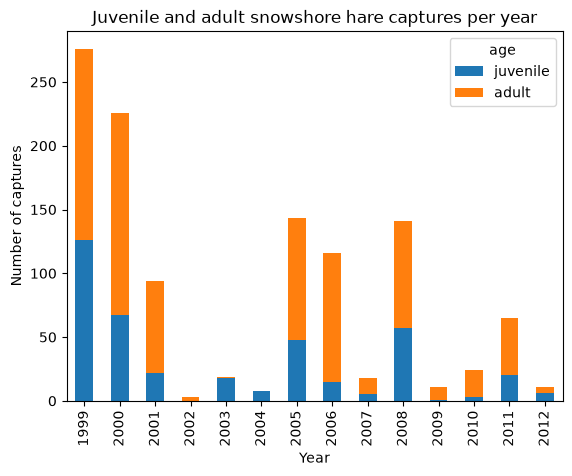

In [28]:
obs_per_year[['juvenile','adult']].plot(kind='bar',
                                        stacked=True,
                                        title='Juvenile and adult snowshore hare captures per year',
                                        xlabel='Year',
                                        ylabel='Number of captures')

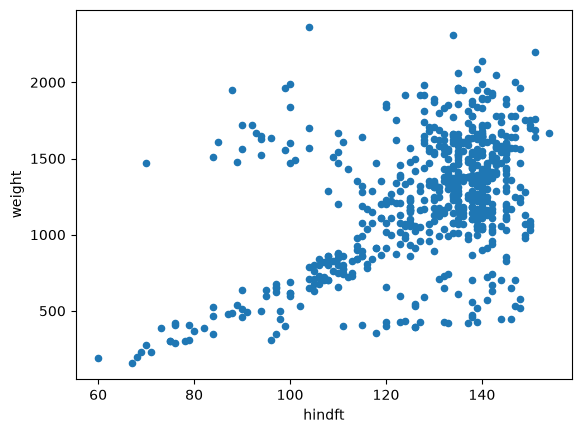

In [34]:
# Initialize empty figure and axes
fig, ax = plt.subplots()

# Add scatter plot of hares' data to our figure's axes
obs_juv_adult.plot(kind='scatter', x='hindft', y='weight', ax=ax)

# Display figure
plt.show()

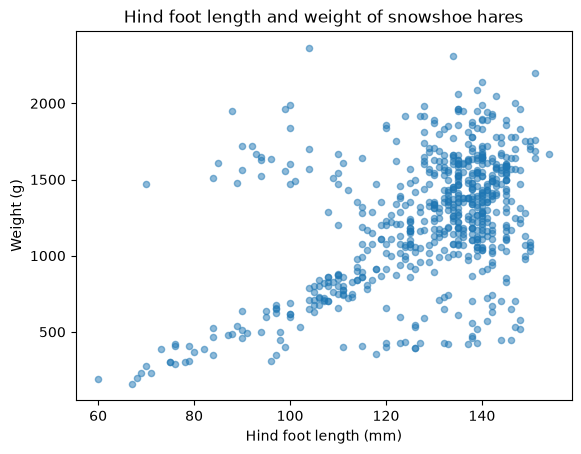

In [35]:
# Initialize empty figure and axes
fig, ax = plt.subplots()

# Add data to axes
obs_juv_adult.plot(kind='scatter', 
                   x='hindft', 
                   y='weight', 
                   alpha=0.5,     # Adjust transparency
                   ax=ax)         # Add plot to axes

# Update axes
ax.set_title('Hind foot length and weight of snowshoe hares')
ax.set_xlabel('Hind foot length (mm)')
ax.set_ylabel('Weight (g)')

# Display figure
plt.show()

## Linear Regression

For our analysis we want to investigate possible relations between hind foot length and weight for juvenile hares. Let’s take a look at our target data:



Number of juvenile hare captures with hind foot and weight measurements: 265


<Axes: xlabel='hindft', ylabel='weight'>

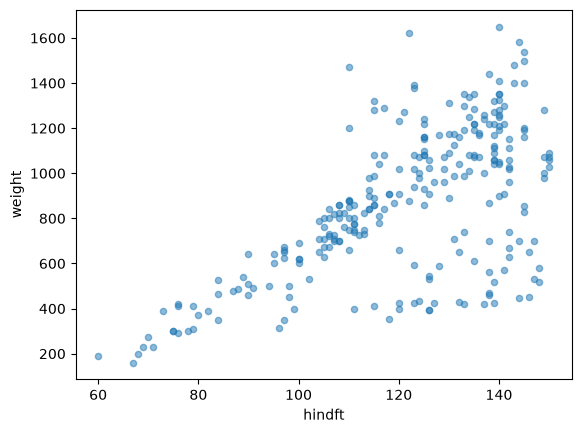

In [36]:
# Subset juvenile hares and drop rows missing hind foot or weight measurements
juv_w_hft = obs_juv_adult[obs_juv_adult['age'] == 'juvenile'].dropna(subset=['hindft', 'weight'])

print("Number of juvenile hare captures with hind foot and weight measurements:", len(juv_w_hft))
juv_w_hft.plot.scatter(x='hindft', y='weight', alpha=0.5)

In [37]:
# Fit model: weight explained by hind foot length

# ols - ordinary least squared
model = smf.ols('weight ~ hindft', data=juv_w_hft).fit()

model.params

Intercept   -352.771986
hindft        10.092240
dtype: float64

In [38]:
# Retrieve parameters
intercept = model.params['Intercept']
slope = model.params['hindft']

print(f'y-intercept: {intercept}')
print(f'slope: {slope}')

y-intercept: -352.77198564640645
slope: 10.092239638623008


In [41]:
print('R^2 is the coefficient of determination.')
print(f'R^2: {model.rsquared}')

R^2 is the coefficient of determination.
R^2: 0.38711647836657315


In [42]:
# smallest and largest hind foot length
x_start = juv_w_hft['hindft'].min()
x_end = juv_w_hft['hindft'].max()

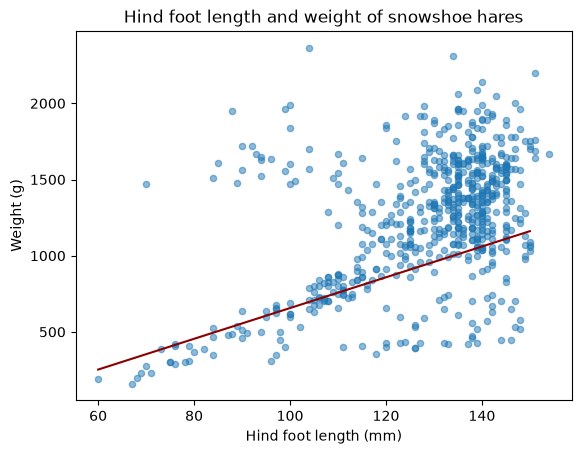

In [43]:
# Initialize empty figure and axes
fig, ax = plt.subplots()

# Add data to axes
obs_juv_adult.plot(kind='scatter', 
                   x='hindft', 
                   y='weight', 
                   alpha=0.5,     # Adjust transparency
                   ax=ax)         # Add plot to axes

# Add regression line to axes
ax.plot([x_start, x_end],
        (intercept + slope * x_start, intercept + slope * x_end),
        color='darkred')

# Update axes
ax.set_title('Hind foot length and weight of snowshoe hares')
ax.set_xlabel('Hind foot length (mm)')
ax.set_ylabel('Weight (g)')

# Display figure
plt.show()

<Axes: title={'center': 'Distribution of residuals'}, xlabel='Residual (g)', ylabel='Frequency'>

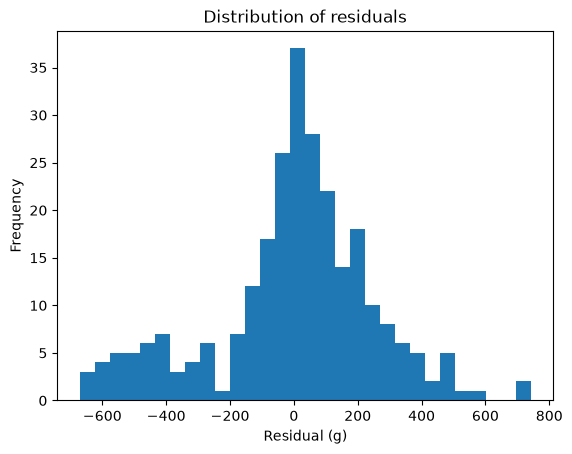

In [ ]:
model.resid.plot(kind='hist', 
                 bins=30, 
                 title='Distribution of residuals', 
                 xlabel='Residual (g)')
# normal distribution around 0
# alot of negative values, model is underestimating the values

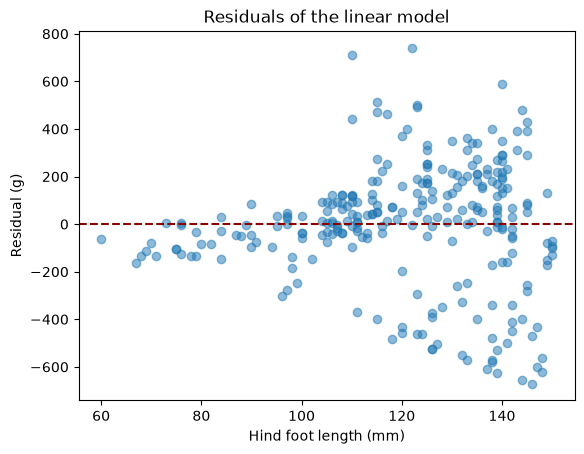

In [46]:
# Initialize empty figure and axes
fig, ax = plt.subplots()

# Add residuals to axes
ax.scatter(juv_w_hft['hindft'], model.resid, alpha=0.5)

# Add reference line at 0
ax.axhline(0, color='darkred', linestyle='--')

# Update axes
ax.set_title('Residuals of the linear model')
ax.set_xlabel('Hind foot length (mm)')
ax.set_ylabel('Residual (g)')

# Display figure
plt.show()